<img src='images/scdries_t02.png' style='width: 1200px; float:center'>



<img src='./images/DIY.jpg' style='width: 100px'>


# ONE EXAMPLE OF COMPLETION

---------
#  Basics on Simple Side-Channel Analysis and first reverse side-channel analysis

--------

* Perform Simple Power Analysis on one and/or several traces (SPA) to recognize the cryptographic algorithm in the traces
* Explain how you recognize it 
* Explain what kind of operations you can identify and where in the traces
* Is the trace containing the whole algorithm computation ? Yes ? No ? All or how many round?
* Apply signal processing such as vertical mean, variance on several traces to remove noise and have a better trace to observe
* Use REVERSE side-channel advanced analysis such as correlation or NICV or ANOVA with the proper selection functions to detect leakage or not for each of the AES main operations: KeyAddition, Shiftrows, SuBbytes, Mixcolumn

----------------
### import

In [1]:
import warnings
import estraces
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [2]:
import plotly.graph_objects as go;
from plotly_resampler import FigureResampler

In [3]:
ths = estraces.read_ths_from_ets_file("../SideSCA-Traces-Public/traces_stm32_set.ets") 
print(ths)

Trace Header Set:
Name.............: ETS Format THS
Reader...........: ETS format reader of file ../SideSCA-Traces-Public/traces_stm32_set.ets with 100 traces.
ciphertext.......: uint8
key..............: uint8
plaintext........: uint8



### Plot and observe traces

In [4]:
fig = FigureResampler(go.Figure())
fig.add_trace(go.Scatter(x=np.arange(len(ths.samples[0])), y=ths.samples[0]))
fig.add_trace(go.Scatter(x=np.arange(len(ths.samples[1])), y=ths.samples[1]))
fig.add_trace(go.Scatter(x=np.arange(len(ths.samples[2])), y=ths.samples[2]))
fig.add_trace(go.Scatter(x=np.arange(len(ths.samples[3])), y=ths.samples[3]))

fig.update_layout(width=1400, height=400)
fig.show_dash( mode='inline')

#fig.update_layout(width=1800, height=900)
#fig.show_dash( mode='external')

<img src='./images/DIY.jpg' style='width: 100px'>


### How to manipulate metadata

In [10]:
#plaintext 
ths.plaintext

array([[241,   5, 224, ..., 249, 213, 228],
       [ 86,  19,  37, ..., 142,   7, 101],
       [125, 109,  71, ...,  20, 177, 166],
       ...,
       [108,  47, 105, ..., 113, 218,  30],
       [ 23, 143, 109, ..., 126, 166,  32],
       [ 94, 221, 115, ...,  32, 172, 136]], shape=(100, 16), dtype=uint8)

In [11]:
# 0 to 5 first plaintexts
ths.plaintext[0:5]

array([[241,   5, 224, 157,  13,  51, 249, 223, 245, 130, 211, 201, 126,
        249, 213, 228],
       [ 86,  19,  37, 223, 229,   0,  19, 110,  26, 158, 118, 104, 145,
        142,   7, 101],
       [125, 109,  71, 189, 145, 210, 238,  18, 117, 237,  69,  33, 112,
         20, 177, 166],
       [ 28, 217,  31, 247, 188,  72,  87, 101, 230, 124, 160,  56, 152,
        128, 159, 158],
       [162, 148,  19, 169, 108,   9, 171, 194,  82,   9, 165,  14, 147,
        112,  37, 164]], dtype=uint8)

In [12]:
# Same with other metadata
ths.key[0:5]

array([[ 43, 126,  21,  22,  40, 174, 210, 166, 171, 247,  21, 136,   9,
        207,  79,  60],
       [ 43, 126,  21,  22,  40, 174, 210, 166, 171, 247,  21, 136,   9,
        207,  79,  60],
       [ 43, 126,  21,  22,  40, 174, 210, 166, 171, 247,  21, 136,   9,
        207,  79,  60],
       [ 43, 126,  21,  22,  40, 174, 210, 166, 171, 247,  21, 136,   9,
        207,  79,  60],
       [ 43, 126,  21,  22,  40, 174, 210, 166, 171, 247,  21, 136,   9,
        207,  79,  60]], dtype=uint8)

In [13]:
ths.ciphertext[0:5]

array([[247, 239, 255,  22, 196, 149,  95,  36, 202, 237, 137, 253, 142,
         12,  65, 132],
       [ 47,   1, 246, 110, 178, 167,   9, 150,  68, 203,  17,  56,   1,
         44, 125, 205],
       [188,  59,   2,  64, 228, 128, 190, 185, 184, 130,  89,  96, 197,
        101,  73,  24],
       [158, 221, 188, 171, 186, 233, 209,  27, 118, 224, 184, 214,  59,
        174, 249, 130],
       [211,  43, 171,  66,  36, 228, 211, 166, 192, 236, 170,  20, 145,
        231,  38, 117]], dtype=uint8)

In [23]:
#Manipulate the traces
ths.samples[0:5]

array([[ 0.10449219, -0.06542969, -0.03417969, ..., -0.08105469,
        -0.046875  , -0.03222656],
       [ 0.09765625, -0.06835938, -0.04199219, ..., -0.08886719,
        -0.05175781, -0.03613281],
       [ 0.10058594, -0.06738281, -0.03808594, ..., -0.08789062,
        -0.05273438, -0.03320312],
       [ 0.1015625 , -0.06640625, -0.0390625 , ..., -0.08398438,
        -0.04394531, -0.03027344],
       [ 0.10449219, -0.06542969, -0.03320312, ..., -0.08789062,
        -0.04980469, -0.03417969]], shape=(5, 8000))

In [24]:
#Length of the traces
len(ths.samples[0])

8000


### Verify the AES computation is correct inside the metadata

In [5]:
import scared

In [8]:
scared.aes.encrypt(ths.plaintext[0],ths.key[0]) == ths.ciphertext[0]

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])

<img src='./images/DIY.jpg' style='width: 100px'>


## Observe the trace 

Open the trace in full screen, zoom and observe

* What do you see?
* What kind of information do you visualize?
* highlight the rounds and the operations


In [14]:
from matplotlib import colors as mcolors


colors = dict(mcolors.BASE_COLORS)
by_hsv = sorted((tuple(mcolors.rgb_to_hsv(mcolors.to_rgba(color)[:3])), name)
                for name, color in colors.items())
sorted_names = [name for hsv, name in by_hsv]

In [70]:
fig = FigureResampler(go.Figure())
fig.add_trace(go.Scatter(x=np.arange(len(ths.samples[0])), y=ths.samples[0]))
fig.update_layout(width=1400, height=400)
fig.show_dash( mode='inline')

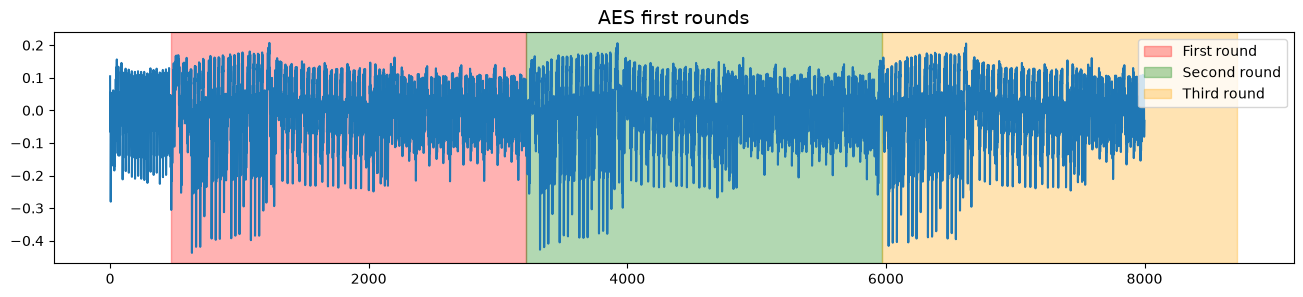

In [71]:
#Choose a trace to visualize
trace = ths.samples[0]

plt.rcParams['figure.figsize']=(16,3)
plt.title('AES first rounds', fontsize=14)    
beg_first_round = 468
round_length = 2750

plt.axvspan(beg_first_round, beg_first_round + round_length, color='red', alpha=0.3, label = 'First round')
plt.axvspan(beg_first_round + round_length, beg_first_round + 2*round_length, color='green', alpha=0.3, label = 'Second round')
plt.axvspan(beg_first_round + 2*round_length, beg_first_round + 3*round_length, color='orange', alpha=0.3, label = 'Third round')

plt.legend(loc='upper right')
plt.plot(trace)
plt.show()

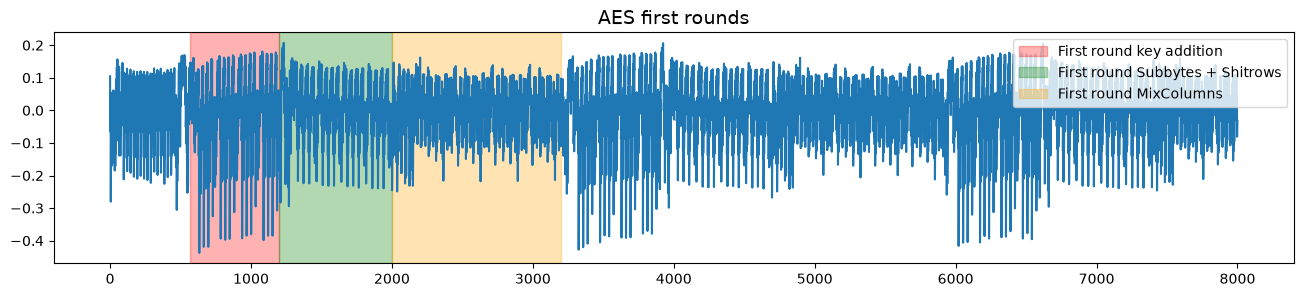

In [79]:
#Choose a trace to visualize
trace = ths.samples[0]

period = 20
plt.rcParams['figure.figsize']=(16,3)
plt.title('AES first rounds', fontsize=14)    
trace_obs = scared.signal_processing.moving_mean(trace, period).T
beg_first_round = 468
round_length = 2750

plt.axvspan(569, 1200, color='red', alpha=0.3, label = 'First round key addition')
plt.axvspan(1200, 2000, color='green', alpha=0.3, label = 'First round Subbytes + Shitrows')
plt.axvspan(2000, 3200, color='orange', alpha=0.3, label = 'First round MixColumns')

plt.legend(loc='upper right')
plt.plot(trace)
plt.show()

- We can identify the area corresponding to the AES round
- Inside an AES round, we can locate the areas for the different operations: KeyAddition, SuBBytes (including shiftrows), and the Mixcolumn.

<img src='./images/DIY.jpg' style='width: 100px'>

---------
## Using signal processing can be very useful to provide better readability
- Applying vertical mean, variance (for instance) on several traces allow to remove noise of the trace and allow identification of operations and sometimes even secrets 
- If only a single trace is available, then (horizontal) moving mean, moving variance or moving kurtosis can lead also to better data analysis and operations and secrets observation 


Compute the mean and the standard deviation on the set of traces

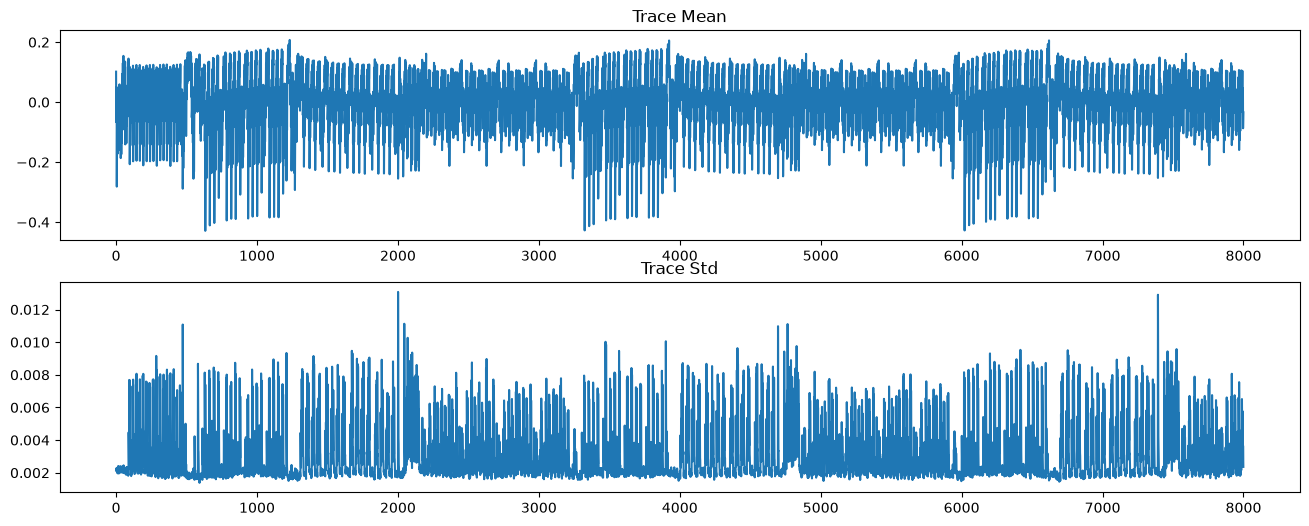

In [96]:
plt.rcParams['figure.figsize']=(16,6)

trace_mean = np.mean(ths.samples[0:100], axis = 0)
trace_std = np.std(ths.samples[0:100], axis = 0)
plt.subplot(2,1,1) 
plt.title("Trace Mean")
plt.plot(trace_mean.T)
plt.subplot(2,1,2) 
plt.title("Trace Std")
plt.plot(trace_std.T)
plt.show()

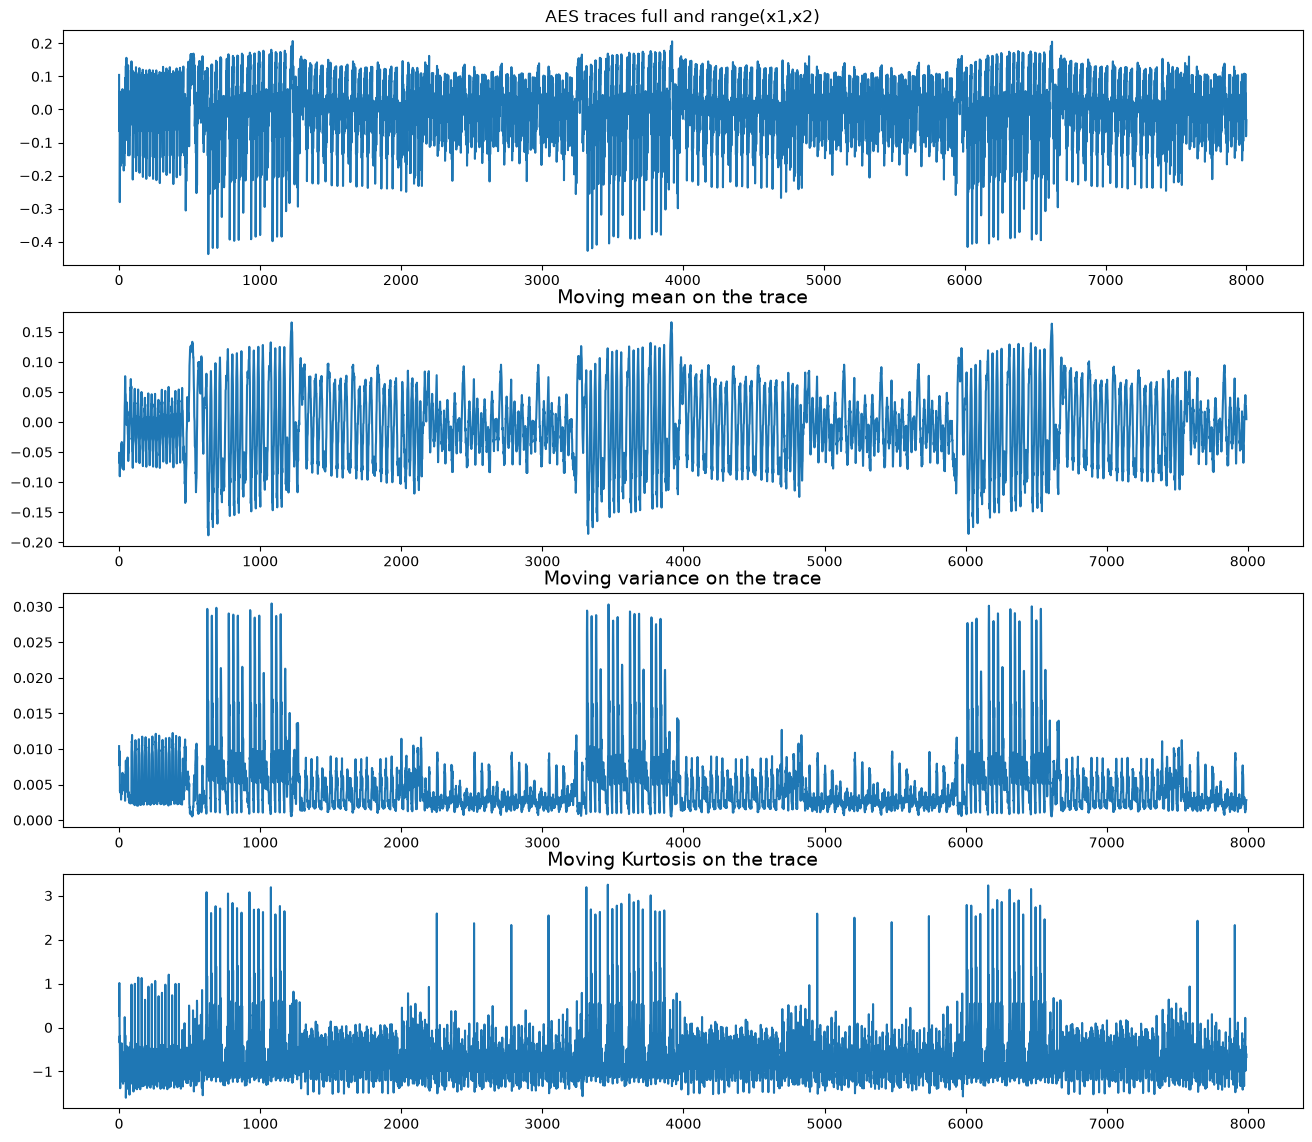

In [86]:
plt.rcParams['figure.figsize']=(16,14)

period = 10 

plt.subplot(4,1,1) 
plt.title('AES traces full and range(x1,x2)') 
plt.plot(ths.samples[0:1].T)

plt.subplot(4,1,2)
plt.title('Moving mean on the trace', fontsize=14)    
trace_moving_mean = scared.signal_processing.moving_mean(trace, period).T
plt.plot(trace_moving_mean)    

plt.subplot(4,1,3)
plt.title('Moving variance on the trace', fontsize=14)    
trace_moving_mean = scared.signal_processing.moving_var(trace, period).T
plt.plot(trace_moving_mean)    

plt.subplot(4,1,4)
plt.title('Moving Kurtosis on the trace', fontsize=14)    
trace_moving_mean = scared.signal_processing.moving_kurtosis(trace, period).T
plt.plot(trace_moving_mean)    

plt.show()

<img src='./images/DIY.jpg' style='width: 100px'>

---------
## Using an open source SCA tool to analyse the trace with side-channel reverse engineering

### Select your model

In [56]:
model_selected=scared.HammingWeight()
#model=scared.Value()
#model=scared.Monobit()    # and set the bit value

### Select your distinguisher

In [57]:
Distinguisher = scared.CPAReverse
#Distinguisher = scared.SNRReverse
#Distinguisher = scared.ANOVAReverse
#Distinguisher = scared.NICVReverse

In [58]:
container = scared.Container(ths)

In [59]:
@scared.reverse_selection_function
def identity_plaintext(plaintext):
    return plaintext

@scared.reverse_selection_function
def identity_ciphertext(ciphertext):
    return ciphertext

In [ ]:
reverse_plaintext = Distinguisher(selection_function=identity_plaintext, model = model_selected)
reverse_ciphertext = Distinguisher(selection_function=identity_ciphertext, model = model_selected)

reverse_plaintext.run(container)
reverse_ciphertext.run(container)

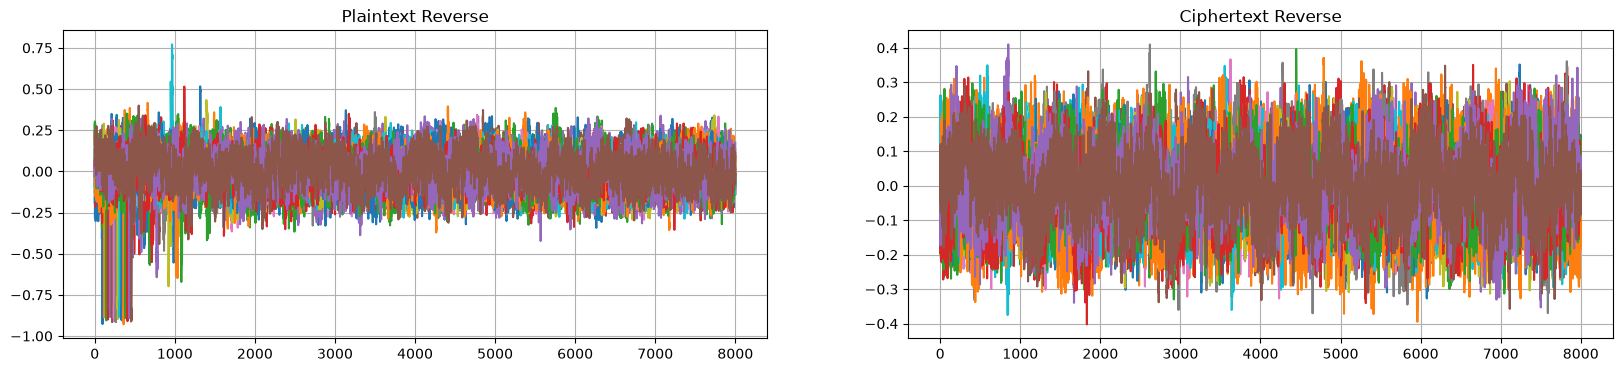

In [91]:
plt.rcParams['figure.figsize']=(20,4)
plt.subplot(121)
plt.grid(True)
plt.plot(reverse_plaintext.results.T)
plt.title('Plaintext Reverse')
plt.subplot(122)
plt.grid(True)
plt.plot(reverse_ciphertext.results.T)
plt.title('Ciphertext Reverse')
plt.show()

----
### Reverse on intermediate values - First round

In [62]:
def aes_function_firstRde_AddKey(plaintext, key):
    return scared.aes.encrypt(plaintext = plaintext, key = key, at_round=0, after_step=scared.aes.base.Steps.ADD_ROUND_KEY)

def aes_function_firstRde_SBout(plaintext, key):
    return scared.aes.encrypt(plaintext = plaintext, key = key, at_round=1, after_step=scared.aes.base.Steps.SUB_BYTES)

def aes_function_firstRde_ShiftRow(plaintext, key):
    return scared.aes.encrypt(plaintext = plaintext, key = key, at_round=1, after_step=scared.aes.base.Steps.SHIFT_ROWS)

def aes_function_firstRde_MixColumn(plaintext, key):
    return scared.aes.encrypt(plaintext = plaintext, key = key, at_round=1, after_step=scared.aes.base.Steps.MIX_COLUMNS)

In [63]:
container = scared.Container(ths)

In [64]:
Sel_AdK = scared.reverse_selection_function(aes_function_firstRde_AddKey)
Sel_SB = scared.reverse_selection_function(aes_function_firstRde_SBout)
Sel_SR = scared.reverse_selection_function(aes_function_firstRde_ShiftRow)
Sel_MXC = scared.reverse_selection_function(aes_function_firstRde_MixColumn)

In [65]:
Reverse_AdK = Distinguisher(selection_function = Sel_AdK, model = model_selected)
Reverse_SB = Distinguisher(selection_function = Sel_SB, model = model_selected)
Reverse_SR = Distinguisher(selection_function = Sel_SR, model = model_selected)
Reverse_MXC = Distinguisher(selection_function = Sel_MXC, model = model_selected)

In [66]:
Reverse_AdK.run(container)
Reverse_SB.run(container)
Reverse_SR.run(container)
Reverse_MXC.run(container)

In [67]:
Reverse_SB.results.shape

(16, 8000)

### Plot results

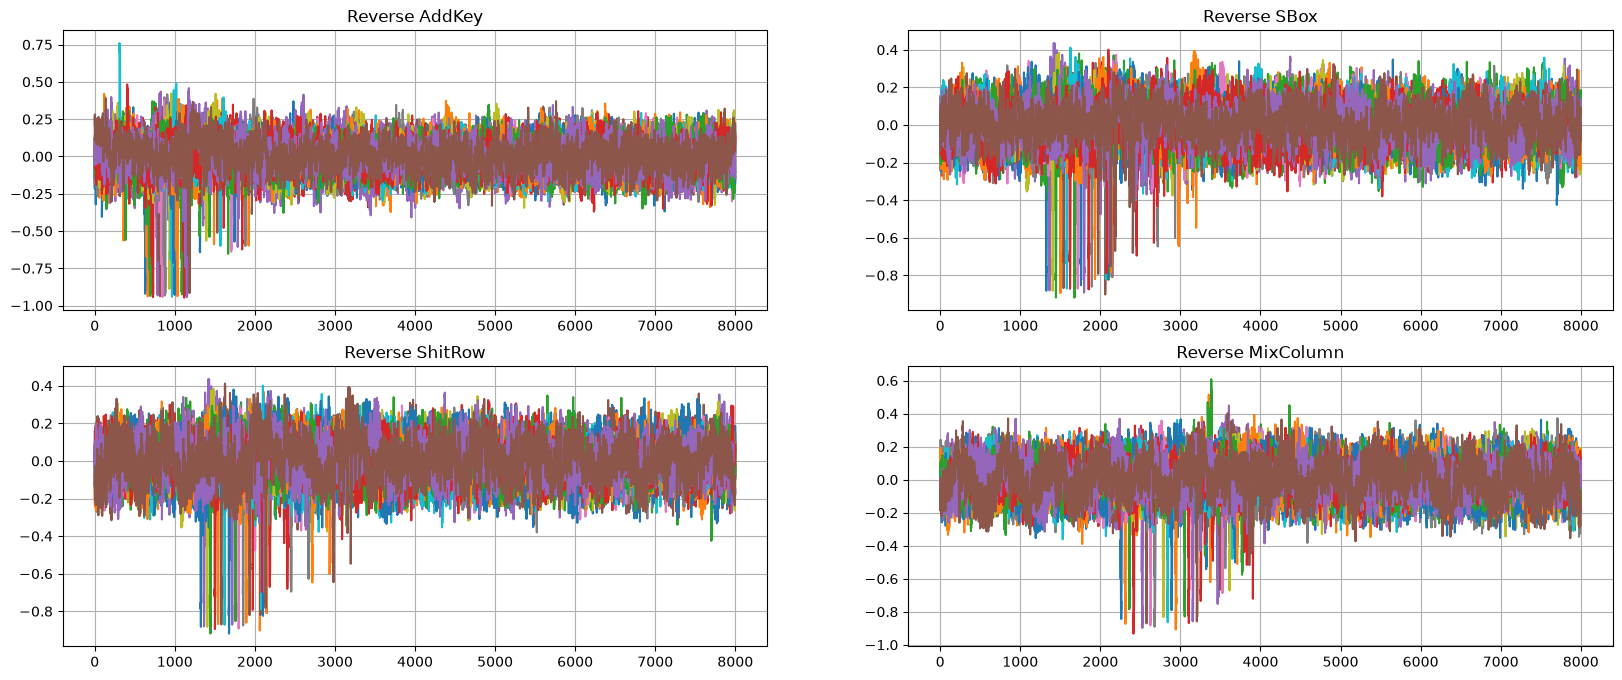

In [88]:
plt.rcParams['figure.figsize']=(20,8)

plt.subplot(221)
plt.grid(True)
plt.plot(Reverse_AdK.results.T)
plt.title('Reverse AddKey')
plt.subplot(222)
plt.grid(True)
plt.plot(Reverse_SB.results.T)
plt.title('Reverse SBox')
plt.subplot(223)
plt.grid(True)
plt.plot(Reverse_SR.results.T)
plt.title('Reverse ShitRow')
plt.subplot(224)
plt.grid(True)
plt.plot(Reverse_MXC.results.T)
plt.title('Reverse MixColumn')

plt.show()

# Conclusion

All AES operations are leaking in the power traces, making it possible to identify the different steps of the algorithm such as SubBytes, ShiftRows, MixColumns, and AddRoundKey.

By analyzing the patterns in the traces, one can distinguish between these operations based on their characteristic power consumption profiles. 

This allows for the recognition of the algorithm and the identification of specific operations within the traces.

